<h4>Industry-Style Agentic RAG with LangGraph</h4>
why this is industry-style
A simple RAG system searches only the private knowledge base
An industry-style Agentic RAG syetem should this
Question
   |
Search private knowledge base first
   |
Grade the prevate evidence
   |
if private evidence is good -> answer from KB
   |
if private evidence is weak -> search the web
   |
Grade web evidence 
   |
generate a grounded answer with source type

This design is useful private docuemnts may be incomplete or outdated


<h4>1. Install Dependencies</h4>

<h4>2. Configure API Keys</h4>

In [1]:
import os
from getpass import getpass
try:
    from dotenv import load_dotenv
    load_dotenv()
except Exception as e:
    pass
if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("Enter your OpenAI API key: ")
if not os.getenv("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass("Enter your GROQ API key: ")
if not os.getenv("PINECONE_API_KEY"):
    os.environ["PINECONE_API_KEY"] = getpass("Enter your Pinecone API key: ")
if not os.getenv("TAVILY_API_KEY"):
    os.environ["TAVILY_API_KEY"] = getpass("Enter your Tavily API key: ")

print("GROQ_API_KEY Configured:", bool(os.getenv("GROQ_API_KEY")))
print("PINECONE_API_KEY Configured:", bool(os.getenv("PINECONE_API_KEY")))
print("TAVILY_API_KEY Configured:", bool(os.getenv("TAVILY_API_KEY")))
print("OPENAI_API_KEY Configured:", bool(os.getenv("OPENAI_API_KEY")))

GROQ_API_KEY Configured: True
PINECONE_API_KEY Configured: True
TAVILY_API_KEY Configured: True
OPENAI_API_KEY Configured: True


<h4>3.Load Real Docuemnts</h4>
we Will create our private knowledge base from a real web docuemnt:

https://docs.langchain.com/oss/python/langgraph/agentic-rag


This becomes our internal/private KB for the DEMO.

. First source : indexed Langgraph documentation page

. fallback source: live web search through Tavily



In [2]:
from langchain_community.document_loaders import WebBaseLoader

SOURCE_URL = "https://docs.langchain.com/oss/python/langgraph/agentic-rag"

loadder = WebBaseLoader(
    web_path=(SOURCE_URL,),
    requests_kwargs={
        "headers": {
        "User-Agent": (
            "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
            "AppleWebKit/537.36 (KHTML, like Gecko) "
            "Chrome/142.0.0.0 Safari/537.36"
        ),
        "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
        "Accept-Language": "en-US,en;q=0.9",
    }
    },
)

raw_documents = loadder.load()
print("Loaded Documents:", len(raw_documents))
print("Source:", raw_documents[0].metadata.get("source"))
print("\nPreview:\n")
print(raw_documents[0].page_content[:1500])  # Print the first 500 characters of the first document



USER_AGENT environment variable not set, consider setting it to identify your requests.


Loaded Documents: 1
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag

Preview:

Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentInterrupt is coming to London on October 13! Get ticketsDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsLangChainMulti-agentLangGraphCustom RAG agentCustom SQL agentConceptual overviewsLangChain vs. LangGraph vs. Deep AgentsProviders and modelsComponent architectureMemoryContextGraph APIFunctional APIAdditional resourcesUse docs programmaticallyLangChain AcademyCase studiesGet helpOn this pageConceptsSetupSet up LangSmithPreprocess documentsCrea

<h4>4. SPlit the documents into chuncks</h4>

In [4]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=150,
    add_start_index=True,
)
documents = splitter.split_documents(raw_documents)
print("Number of Chunks:", len(documents))
print("Preview of First Chunk:\n")
print(documents[0].page_content[:500])  # Print the first 500 characters of the first chunk

Number of Chunks: 28
Preview of First Chunk:

Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentInterrupt is coming to London on October 13! Get ticketsDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegration


<h4>5.Create Free Local Embeddings</h4>

In [7]:

from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True}
)

sample_vector = embeddings.embed_query("Hello, world!")

print("Sample Vector Length:", len(sample_vector))


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Sample Vector Length: 384


In [9]:
#sample_vector

<h4>6.Create the PinceCone vector DataBase</h4>
The Embedding model used in this notebook 384-Dimensional vectors , so pincone index must use Dimension 384

In [ ]:
from pinecone import Pinecone,ServerlessSpec
from langchain_pinecone import PineconeVectorStore
import time

INDEX_NAME = "industry-agentic-rag-kb"
NAMESPACE = "langgraph-agentic-rag"

#Connect to Pinecone
pc = Pinecone(api_key=os.environ.get("PINECONE_API_KEY"))

# Check if the index already exists create it if it doesn't exist
existing_indexes = [index_info["name"] for index_info in pc.list_indexes()]

if INDEX_NAME not in existing_indexes:
    pc.create_index(
        name=INDEX_NAME,
        dimension=384, # all-MiniLM-L6-v2 model produces 384-dimensional embeddings
        metric="cosine",
        spec=ServerlessSpec(cloud="aws", region="us-east-1"),
        deletion_protection="enabled",  # Defaults to "disabled"
    )
    while not pc.describe_index(INDEX_NAME).status["ready"]:
        time.sleep(1)
    
print("Pinecone Index is ready:", INDEX_NAME)
# upload the documents to Pinecone create a Pinecone vector store from the documents and embeddings
vector_store = PineconeVectorStore.from_documents(
    documents=documents,
    embedding=embeddings,
    index_name=INDEX_NAME,
    namespace=NAMESPACE,
)
retriver = vector_store.as_retriever(search_kwargs={"k": 4, "namespace": NAMESPACE})
print("pinecone VDB  and retriver is ready:",)

Pinecone Index is ready: industry-agentic-rag-kb
pinecone VDB  and retriver is ready:


In [11]:
retriver = vector_store.as_retriever(search_kwargs={"k": 4, "namespace": NAMESPACE})
print("pinecone VDB  and retriver is ready:",)

pinecone VDB  and retriver is ready:


In [13]:
#Load Existing Index
from pinecone import Pinecone
import os
from pinecone import Pinecone
from langchain_pinecone import PineconeVectorStore

# Connect to Pinecone
pc = Pinecone(
    api_key=os.environ["PINECONE_API_KEY"]
)

# Load the existing index
INDEX_NAME = "industry-agentic-rag-kb"
NAMESPACE = "langgraph-agentic-rag"
index = pc.Index(INDEX_NAME)

# Initialize your embedding model (already created as embeddings)
vector_store = PineconeVectorStore(
    index=index,
    embedding=embeddings,
    namespace=NAMESPACE
)
#create a retriever from the vector store
retriever = vector_store.as_retriever(search_kwargs={"k": 4, "namespace": NAMESPACE})
print("Existing pinecone VDB and retriever is ready:", INDEX_NAME)

Existing pinecone VDB and retriever is ready: industry-agentic-rag-kb


<h4>7.Test Private KB Retrival</h4>

In [15]:

test_question = "What happens if retrieved docuemnts are not relevant in Agentic RAG ?"
kb_docs = retriever.invoke(test_question)
for i, doc in enumerate(kb_docs):
    print(f"Document {i+1}:\n")
    print(doc.page_content[:700])  # Print the first 500 characters of each retrieved document
    print("Source",doc.metadata.get("source"))
    print("\n" + "-"*80 + "\n")  # Separator between documents

Document 1:

Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentInterrupt is coming to London on October 13! Get ticketsDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsLangChainMulti-agentLangGraphCustom RAG agentCustom SQL agentConceptual overviewsLangChain vs. LangGraph vs. Deep AgentsProviders and modelsComp
Source https://docs.langchain.com/oss/python/langgraph/agentic-rag

--------------------------------------------------------------------------------

Document 2:

pageConceptsSetupSet up LangSmithPreprocess documentsCreate a retriever toolGenerate a query or respondGrade documentsRewri

In [42]:
from langchain_groq import ChatGroq
from langchain_openai import ChatOpenAI

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    # max_output_tokens=512,
    #api_key=os.environ.get("GROQ_API_KEY"),
)
answer_llm = ChatOpenAI(
    model_name="gpt-4o",
    temperature=0,
    # max_output_tokens=512,
    #api_key=os.environ.get("OPENAI_API_KEY"),
)
print(llm.invoke("Explain the Agentic RAG in one sentence").content)
print(answer_llm.invoke("Explain the Agentic RAG in one sentence").content)

Agentic RAG is a retrieval‑augmented generation framework in which an autonomous agent actively selects, fetches, and incorporates relevant external knowledge on the fly to produce more accurate, context‑aware responses.
Agentic RAG (Retrieval-Augmented Generation) is a framework that combines information retrieval with generative AI to enhance the accuracy and relevance of generated responses by incorporating external knowledge sources.


<h4>Initialize the Tavily web search</h4>
This is used when private KB is insufficent
this is important because we do not want to send every private/company question to the public web


In [18]:
from langchain_community.tools.tavily_search import TavilySearchResults
tavily_tool = TavilySearchResults(max_results=5,
                                  topic = "general",
                                  include_answer=True,
                                  include_raw_content=False)

print("Tavily web search tool initialized. It will be used when private KB is insufficient.")

Tavily web search tool initialized. It will be used when private KB is insufficient.


/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_5218/2601924852.py:2: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily_tool = TavilySearchResults(max_results=5,


<h4>10.Define the structured Decision</h4>

We need reliable yes/no or route outputs from the LLM


In [101]:
from typing import List , Literal,Optional
from typing_extensions import Annotated, TypedDict
from pydantic import BaseModel, Field
from langchain_core.documents import Document

#Crete Pydantic models for structured decision making
class RouteDecision(BaseModel):
    route: Literal["kb", "direct"] = Field(description="The route decision, either 'kb' for knowledge base or 'direct' for direct answer. 'kb' means the agent should use the knowledge base to find relevant information, 'direct' means the agent should provide a direct answer without using the knowledge base.")
    
class EvidenceGrade(BaseModel):
    grade: Literal["good", "weak"] = Field(description="The grade of the evidence, either 'good' or 'weak' good means the evidence is relevant and reliable, weak means it is not.")

#Create a TypedDict for the agent state it will be used to store the state of the agent during the decision making process
class AgentState(TypedDict):
    question:str
    current_query:str
    kb_docs: List[Document]
    web_results: str
    kb_grade:str
    web_grade:str
    answer:str
    source_used:str
    retry_count:int


11. Node 1 - Route the question

The Router decides :

.KB: Use private knowledge base

.direct: answer without retrieval


In [102]:

from langchain_core.prompts import ChatPromptTemplate

def route_question(state: AgentState):
    question = state["question"]

    # 1. Define the router prompt
    router_prompt = ChatPromptTemplate.from_messages([
        (
            "system",
            """
            You are a router for an Agentic RAG assistant.

            Route to "kb" for questions about:
            - Agentic RAG and LangGraph workflows
            - Retrieval grading and query rewriting
            - RAG architecture and retriever tools
            - Web fallback in RAG
            - Other informational or technical questions

            Route to "direct" only for:
            - Greetings
            - Thanks
            - Simple conversation

            Return your response as valid JSON.
            The JSON must contain exactly one field:
            "route", with value "kb" or "direct".

            Example: {{"route": "kb"}}
            """
        ),
        ("human", "{question}")
    ])

    # 2. Create the structured LLM chain
    router_chain = (
        router_prompt
        | llm.with_structured_output(
            RouteDecision,
            method="json_mode"
        )
    )

    # 3. Invoke the router
    decision = router_chain.invoke({
        "question": question
    })

    # 4. Return updated state
    return {
        "current_query": question,
        "source_used": decision.route
    }


In [23]:
state = {
    "question": "Explain Agentic AI, its components, design patterns, applications and challenges"
}
result = route_question(state)
print(result)

{'current_query': 'Explain Agentic AI, its components, design patterns, applications and challenges', 'source_used': 'kb'}


In [103]:
def route_after_router(state: AgentState) -> Literal["retrive_kb", "direct_answer"]:
    if state["source_used"] == "kb":
        return "retrive_kb"
    return "direct_answer"

In [25]:
state = {'current_query': 'Explain Agentic AI, its components, design patterns, applications and challenges', 'source_used': 'kb'}
result  = route_after_router(state)
print(result)

retrive_kb


<h4>12. Node 2 - Retrieve from the private KB


In [104]:
def retrieve_kb(state: AgentState):
    query = state["current_query"]
    kb_docs = retriever.invoke(query)
    print(f"[KB Retrieval] query: '{query}'")
    print(f"[KB Retrieval] Retrieved {len(kb_docs)} chunks.")
    return {
        "kb_docs": kb_docs,
    }

In [63]:
state = {'current_query': 'How to Create a retriever tool'}
result  = retrieve_kb(state)
print(result)

[KB Retrieval] query: 'How to Create a retriever tool'
[KB Retrieval] Retrieved 4 chunks.
{'kb_docs': [Document(id='d7f27f66-e65b-4254-9f19-6027dba1ab04', metadata={'description': 'Build a custom retrieval agent with LangGraph that decides when to search a vector store or respond directly.', 'language': 'en', 'source': 'https://docs.langchain.com/oss/python/langgraph/agentic-rag', 'start_index': 18760.0, 'title': 'Build a custom RAG agent with LangGraph - Docs by LangChain'}, page_content='\u200bSee also\n\nRetrieval\nGraph API\nAgents\nBuild a RAG agent\nBuild a semantic search engine\n\n\nConnect these docs to your agent of choice via MCP for real-time answers.Edit this page on GitHub or file an issue.Was this page helpful?YesNoBuild a SQL assistant with on-demand skillsPreviousBuild a custom SQL agentNextDocs by LangChain home pagegithubxlinkedinyoutubeResourcesForumChangelogLangChain AcademyContact SalesCompanyHomeTrust CenterCareersBloggithubxlinkedinyoutube'), Document(id='ccb321

<h4>13. Node 3- Grade Private KB Evidence</h4>

This is the key step that decides whether we can from the private KB or need call Tavily

In [105]:

def grade_kb_evidence(state: AgentState):
    question = state["question"]

    # 1. Prepare the KB evidence
    context = "\n\n".join(
        f"Source: {doc.metadata.get('source', 'Unknown')}\n"
        f"Content: {doc.page_content}"
        for doc in state["kb_docs"]
    )

    # 2. Define the grader prompt
    grader_prompt = ChatPromptTemplate.from_messages([
        (
            "system",
            """
            You are an evidence grader for an Agentic RAG assistant.

            Evaluate whether the private KB evidence can answer
            the user's question.

            - Return "good" if the evidence is relevant and sufficient
              to answer the question.
            - Return "weak" if the evidence is irrelevant or incomplete
              and cannot answer the question.

            Return your response as valid JSON.
            Example:
            {{"grade": "good"}}

            The grade must be either "good" or "weak".
            Do not include additional text or markdown.
            """
        ),
        (
            "human",
            """
            Question:
            {question}

            Private KB evidence:
            {context}
            """
        )
    ])

    # 3. Configure structured output
    kb_grader_llm = llm.with_structured_output(
        EvidenceGrade,
        method="json_mode"
    )

    # 4. Create the grader chain
    kb_grader_chain = grader_prompt | kb_grader_llm

    # 5. Invoke the grader
    grade = kb_grader_chain.invoke({
        "question": question,
        "context": context
    })

    print("[KB Grader]", grade.grade)

    # 6. Return the updated state
    return {
        "kb_grade": grade.grade
    }


In [29]:

kb_docs = [Document(id='d7f27f66-e65b-4254-9f19-6027dba1ab04', metadata={'description': 'Build a custom retrieval agent with LangGraph that decides when to search a vector store or respond directly.', 'language': 'en', 'source': 'https://docs.langchain.com/oss/python/langgraph/agentic-rag', 'start_index': 18760.0, 'title': 'Build a custom RAG agent with LangGraph - Docs by LangChain'}, page_content='\u200bSee also\n\nRetrieval\nGraph API\nAgents\nBuild a RAG agent\nBuild a semantic search engine\n\n\nConnect these docs to your agent of choice via MCP for real-time answers.Edit this page on GitHub or file an issue.Was this page helpful?YesNoBuild a SQL assistant with on-demand skillsPreviousBuild a custom SQL agentNextDocs by LangChain home pagegithubxlinkedinyoutubeResourcesForumChangelogLangChain AcademyContact SalesCompanyHomeTrust CenterCareersBloggithubxlinkedinyoutube'), Document(id='ccb32119-73e7-4b55-8efe-1647c566f0f7', metadata={'description': 'Build a custom retrieval agent with LangGraph that decides when to search a vector store or respond directly.', 'language': 'en', 'source': 'https://docs.langchain.com/oss/python/langgraph/agentic-rag', 'start_index': 1608.0, 'title': 'Build a custom RAG agent with LangGraph - Docs by LangChain'}, page_content='Fetch and preprocess documents for retrieval.\nIndex those documents for semantic search and create a retriever tool for the agent.\nBuild an agentic RAG system that can decide when to use the retriever tool.\n\n\n\u200bConcepts\nThis tutorial covers the following concepts:\n\nRetrieval using\n\ndocument loaders,\ntext splitters, embeddings, and\nvector stores\n\n\nThe LangGraph Graph API, including state, nodes, edges, and conditional edges.\n\n\u200bSetup\nInstall the required packages and set your API keys:\npip install -U langgraph langchain langchain-openai langchain-text-splitters beautifulsoup4 requests\n\nimport getpass\nimport os\n\n\ndef _set_env(key: str) -> None:\n    if key not in os.environ:\n        os.environ[key] = getpass.getpass(f"{key}:")\n\n\n_set_env("OPENAI_API_KEY")'), Document(id='dd0e4410-1ff6-4cfd-b939-990ad46c7392', metadata={'description': 'Build a custom retrieval agent with LangGraph that decides when to search a vector store or respond directly.', 'language': 'en', 'source': 'https://docs.langchain.com/oss/python/langgraph/agentic-rag', 'start_index': 4494.0, 'title': 'Build a custom RAG agent with LangGraph - Docs by LangChain'}, page_content='from langchain_core.vectorstores import InMemoryVectorStore\nfrom langchain_openai import OpenAIEmbeddings\n\n\n@lru_cache(maxsize=1)\ndef _get_retriever():\n    vectorstore = InMemoryVectorStore.from_documents(\n        documents=doc_splits,\n        embedding=OpenAIEmbeddings(),\n    )\n    return vectorstore.as_retriever()\n2Create the retriever toolCreate a retriever tool using the @tool decorator:from langchain.tools import tool\n\n\n@tool\ndef retrieve_blog_posts(query: str) -> str:\n    """Search and return information about Lilian Weng blog posts."""\n    retriever = _get_retriever()\n    retrieved_docs = retriever.invoke(query)\n    return "\\n\\n".join([doc.page_content for doc in retrieved_docs])\n\n\nretriever_tool = retrieve_blog_posts\n3Test the toolretriever_tool.invoke({"query": "types of reward hacking"})\n\n\u200bGenerate a query or respond\nWith the retriever tool ready, start building the agent as a LangGraph graph. In the Graph API, a graph is made of:')]

state = {
    "question": "How to Create a retriever tool",
    "kb_docs": kb_docs
}
result = grade_kb_evidence(state)
print(result)

[KB Grader] good
{'kb_grade': 'good'}


In [106]:
def decide_after_kb_grade(state: AgentState) -> Literal["generate_from_kb", "search_web"]:
    if state["kb_grade"] == "good":
        return "generate_from_kb"
    return "search_web"

14. Node 4- Tavily web search Fallback

This node runs only when the private KB evidence is weak

we search the web using the original question or the current rewritten query if a rewrite already happened

In [107]:
def search_web(state: AgentState):
    query = state["current_query"]

    print(f"[Tavily Search] Query: {query}")

    result = tavily_tool.invoke(query)

    # Tavily can return dict/list structures depending on package version.
    # Convert it into readable text for grading and generation.
    if isinstance(result, dict):
        answer = result.get("answer", "")
        results = result.get("results", [])
        lines = []
        if answer:
            lines.append(f"Tavily answer: {answer}")

        for item in results:
            title = item.get("title", "")
            url = item.get("url", "")
            content = item.get("content", "")
            lines.append(f"Title: {title}\nURL: {url}\nContent: {content}")

        web_text = "\n\n".join(lines) if lines else str(result)
    else:
        web_text = str(result)

    print("[Tavily Search] Result characters:", len(web_text))

    return {
        "web_results": web_text,
        "source_used": "web",
    }

In [32]:
state = {
    "current_query": "Explain Agentic AI, its components, design patterns, applications and challenges"
}
result = search_web(state)
print(result)

[Tavily Search] Query: Explain Agentic AI, its components, design patterns, applications and challenges
[Tavily Search] Result characters: 10513
{'web_results': '[{\'title\': \'Agentic AI Design Patterns Introduction and walkthrough | Amazon Web Services\', \'url\': \'https://www.youtube.com/watch?v=MrD9tCNpOvU\', \'content\': "problems. Agentic AI workflows represent a significant leap forward and a paradigm shift in AI systems design with features including autonomy, adaptability, and decision making. At the core of agentic AI workflows are key design patterns that enable large language models to exhibit more autonomous and intelligent behavior. These key design patterns are reflection, tool use, planning, and multi-agent. Reflection enhances AI\'s ability to evaluate and improve its own outputs. Through this, AI can provide more accurate and reliable results. The tool use pattern enables AI to expand its capabilities by utilizing external tools and resources. Planning pattern is par

<h4>15. Node5 - Grade Web Evidence

In [108]:

def grade_web_evidence(state: AgentState):
    question  = state["question"]
    web_results = state["web_results"]
    
    web_grader_prompt = ChatPromptTemplate.from_messages([
        (
            "system",
            """
            You are an evidence grader..

            Evaluate whether the web search evidence can answer
            the user's question.

            - Return "good" if the evidence is relevant and sufficient
              to answer the question.
            - Return "weak" if the evidence is irrelevant or incomplete
              and cannot answer the question.

            Return your response as valid JSON.
            Example:
            {{"grade": "good"}}

            The grade must be either "good" or "weak".
            Do not include additional text or markdown.
            """
        ),
        (
            "human",
            """
            Question:
            {question}

            Web search evidence::
            {web_results}
            """
        )
    ])
     # 3. Configure structured output
    web_grader_llm = llm.with_structured_output(
        EvidenceGrade,
        method="json_mode"
    )

    # 4. Create the grader chain
    web_grader_chain = web_grader_prompt | web_grader_llm

    # 5. Invoke the grader
    grade = web_grader_chain.invoke({
        "question": question,
        "web_results": web_results
    })

    print("[KB Grader]", grade.grade)

    # 6. Return the updated state
    return {
        "web_grade": grade.grade
    }

In [109]:
import json as JSON
web_res = JSON.dumps([{'title': 'Agentic AI Design Patterns Introduction and walkthrough | Amazon Web Services', 'url': 'https://www.youtube.com/watch?v=MrD9tCNpOvU', 'content': 'problems. Agentic AI workflows represent a significant leap forward and a paradigm sh... to see if the AI was getting it right. As', 'score': 0.8312667}, {'title': 'Agentic AI Design Patterns Introduction and walkthrough | Amazon Web Services', 'url': 'https://www.youtube.com/watch?v=MrD9tCNpOvU&xstg=CAMSBhUD-7L2Hw%3D%3D', 'content': '77,508 views\nPosted: 2025-06-18\nThe video explores four foundational design patterns ...ific data sets to solve specific problems.', 'score': 0.8201387}, {'title': 'Agentic AI Architecture: Types, Components & Best Practices', 'url': 'https://www.exabeam.com/explainers/agentic-ai/agentic-ai-architecture-types-components-best-practices', 'content': 'This design offers versatility, providing the structure of a leader when needed, whil...s in a continuous loop of problem-solving.', 'score': 0.81979275}, {'title': 'Enterprise AI Agents: Agentic Design Patterns Explained', 'url': 'https://www.tungstenautomation.com/blog/build-enterprise-grade-ai-agents-agentic-design-patterns', 'content': 'In many ways, Agentic AI Design Patterns are the new "design language" of modern AI d...agentic AI different from prompt-based AI?', 'score': 0.77873385}, {'title': 'The Roadmap to Mastering Agentic AI Design Patterns', 'url': 'https://machinelearningmastery.com/the-roadmap-to-mastering-agentic-ai-design-patterns', 'content': 'Agentic design patterns are reusable approaches for recurring problems in agentic sys...w patterns layer together in real systems.', 'score': 0.76554126}])
state = {
    "question": "Explain Agentic AI, its components, design patterns, applications and challenges",
    "web_results": web_res
}
result = grade_web_evidence(state)
print(result)

[KB Grader] weak
{'web_grade': 'weak'}


In [110]:
# conditional decision making after web grading
MAX_RETRIES = 1

def decide_after_web_grade(state: AgentState) -> Literal["generate_from_web", "rewrite_query", "answer_insufficient"]:
    if state["web_grade"] == "good":
        return "generate_from_web"

    if state["retry_count"] < MAX_RETRIES:
        return "rewrite_query"

    return "answer_insufficient"

16. Node 6 — Rewrite the Query
If both KB and web evidence are weak, we rewrite once and then try the KB again.

Why back to KB first?

Because the rewritten query may help retrieve better private evidence before relying on web search again.

In [111]:
from langchain_core.prompts import ChatPromptTemplate


def rewrite_query(state: AgentState):
    question = state["question"]
    retry_count = state["retry_count"] + 1

    # 1. Define the query rewriting prompt
    rewrite_prompt = ChatPromptTemplate.from_messages([
        (
            "system",
            """
            You are a query rewriting assistant for an Agentic RAG system.

            Rewrite the user's question to improve retrieval from the
            knowledge base and web search.

            Rules:
            - Preserve the original intent.
            - Make the query specific and search-friendly.
            - Include relevant technical terms where appropriate.
            - Do not answer the question.
            - Return only the rewritten query.
            """
        ),
        (
            "human",
            """
            Original question:
            {question}
            """
        )
    ])

    # 2. Create the LLM chain
    rewrite_chain = rewrite_prompt | llm

    # 3. Invoke the chain
    response = rewrite_chain.invoke({
        "question": question
    })

    rewritten = response.content.strip()

    print("[Rewriter]", rewritten)

    # 4. Return the updated state
    return {
        "current_query": rewritten,
        "retry_count": retry_count,
    }

17. Node 7 — Generate from Private KB

In [112]:
def generate_from_kb(state: AgentState):
    question = state["question"]

    context = "\n\n".join(
        f"[KB Source: {doc.metadata.get('source')}]\n{doc.page_content}"
        for doc in state["kb_docs"]
    )
    kb_answer_prompt = ChatPromptTemplate.from_messages([
        (
            "system",
            """
            You are a technical instructor.

        Answer using ONLY the private KB context.

        Rules:
        - Beginner-friendly explanation.
        - Do not invent unsupported details.
        - Mention that the answer is based on the private KB.
        - Include source type: Private KB.
            """
        ),
        (
            "human",
            """
            Question:
            {question}

            Private KB evidence:
            {context}
            """
        )
    ])
    # 2. Create the LLM chain
    kb_answer_chain = kb_answer_prompt | llm

    # 3. Invoke the chain
    response = kb_answer_chain.invoke({
        "question": question,
        "context": context
    })

    answer = response.content.strip()

    print("[private_KB_answer]", answer)

    # 4. Return the updated state
    return {
        "answer": answer,
        "source_used": "private_kb",
    }
    

18. Node 8 — Generate from Web Search

In [113]:
def generate_from_web(state: AgentState):
    question = state["question"]
    context = state["web_results"]
    
    web_answer_prompt = ChatPromptTemplate.from_messages([
        (
            "system",
            """
            You are a technical instructor.

            The private KB was insufficient, so web search was used.

            Answer using ONLY the web search context.

            Rules:
            - Beginner-friendly explanation.
            - Do not invent unsupported details.
            - Mention that the answer is based on Tavily web search.
            - Include source type: Web Search.
            - If URLs are present in context, include the most useful URLs.
            """
        ),
        (
            "human",
            """
            Question:
            {question}

            Web search context:
            {context}
            """
        )
    ])
    # 2. Create the LLM chain
    web_answer_chain = web_answer_prompt | llm

    # 3. Invoke the chain
    response = web_answer_chain.invoke({
        "question": question,
        "context": context
    })

    answer = response.content.strip()

    print("[web answer]", answer)

    # 4. Return the updated state
    return {
        "answer": answer,
        "source_used": "web_search",
    }

    

19. Node 9 — Direct Answer

In [114]:
def direct_answer(state: AgentState):
    question = state["question"]

    direct_answer_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
        Respond briefly and naturally. 
        """
    ),(
        "human",
        """
        Question:
        {question}
        """
    )])
    # 2. Create the LLM chain
    web_answer_chain = direct_answer_prompt | llm

    # 3. Invoke the chain
    response = web_answer_chain.invoke({
        "question": question,
    })

    answer = response.content.strip()

    print("[direct answer]", answer)

    # 4. Return the updated state
    return {
        "answer": answer,
        "source_used": "direct",
    }
   

20. Node 10 — Insufficient Evidence Answer

In [115]:
def answer_insufficient(state: AgentState):
    answer = (
        "I could not find enough reliable evidence in the private knowledge base "
        "or the web search results to answer this confidently. "
        "Please provide more specific documents or rephrase the question."
    )

    return {
        "answer": answer,
        "source_used": "insufficient_evidence",
    }

21. Build the LangGraph Workflow

In [116]:
from langgraph.graph import StateGraph,START, END
agentic_rag_graph_workflow = StateGraph(AgentState)
agentic_rag_graph_workflow.add_node("route_question",route_question)
agentic_rag_graph_workflow.add_node("retrieve_kb",retrieve_kb)
agentic_rag_graph_workflow.add_node("grade_kb_evidence",grade_kb_evidence)
agentic_rag_graph_workflow.add_node("generate_from_kb",generate_from_kb)
agentic_rag_graph_workflow.add_node("search_web",search_web)
agentic_rag_graph_workflow.add_node("grade_web_evidence",grade_web_evidence)
agentic_rag_graph_workflow.add_node("generate_from_web",generate_from_web)
agentic_rag_graph_workflow.add_node("rewrite_query",rewrite_query)
agentic_rag_graph_workflow.add_node("direct_answer",direct_answer)  
agentic_rag_graph_workflow.add_node("answer_insufficient",answer_insufficient)
agentic_rag_graph_workflow.add_edge(START,"route_question")
agentic_rag_graph_workflow.add_conditional_edges(
    "route_question",
    route_after_router,
    {
        "retrive_kb": "retrieve_kb",
        "direct_answer": "direct_answer"
    }
)
agentic_rag_graph_workflow.add_edge("retrieve_kb","grade_kb_evidence")
agentic_rag_graph_workflow.add_conditional_edges(
    "grade_kb_evidence",
    decide_after_kb_grade,
    {
        "generate_from_kb": "generate_from_kb",
        "search_web": "search_web"
    }
)
agentic_rag_graph_workflow.add_edge("search_web","grade_web_evidence")
agentic_rag_graph_workflow.add_conditional_edges(
    "grade_web_evidence",
    decide_after_web_grade,
    {
        "generate_from_web": "generate_from_web",
        "rewrite_query": "rewrite_query",
        "answer_insufficient": "answer_insufficient"
    }
)
agentic_rag_graph_workflow.add_edge("rewrite_query","retrieve_kb")
agentic_rag_graph_workflow.add_edge("generate_from_kb",END)
agentic_rag_graph_workflow.add_edge("generate_from_web",END)
agentic_rag_graph_workflow.add_edge("direct_answer",END)    
agentic_rag_graph_workflow.add_edge("answer_insufficient",END)
app = agentic_rag_graph_workflow.compile()
print("Graph compiled successfully.")

Graph compiled successfully.


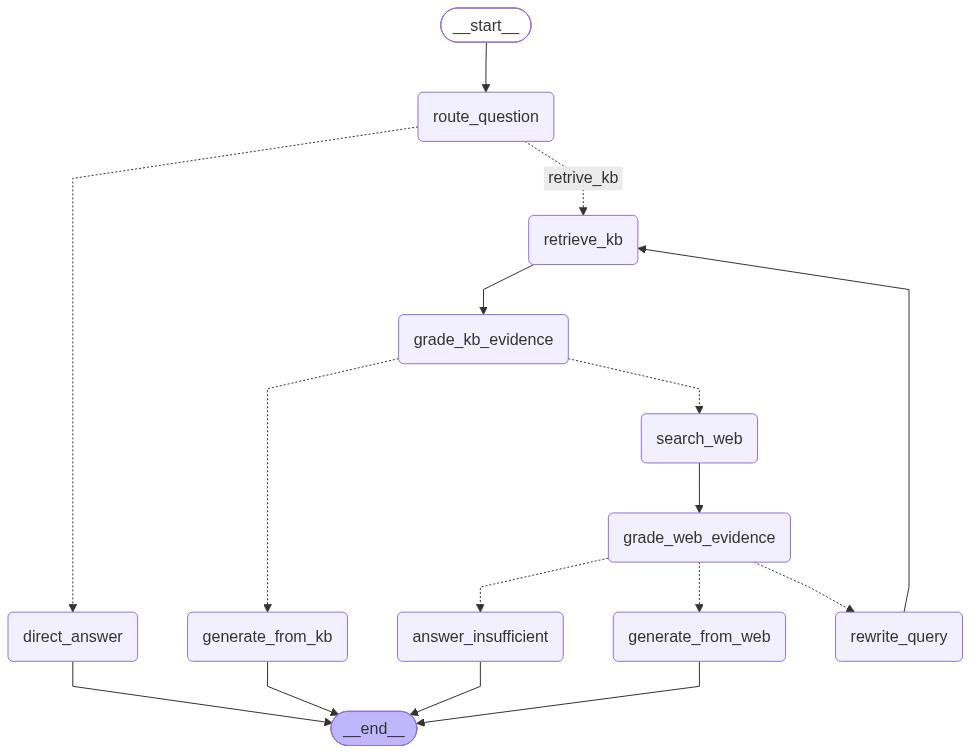

In [120]:
from IPython.display import Image, display,Markdown

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    print(app.get_graph().draw_mermaid())

23. Helper Function

In [118]:
def ask_agent(question: str):
    initial_state: AgentState = {
        "question": question,
        "current_query": question,
        "kb_docs": [],
        "web_results": "",
        "kb_grade": "",
        "web_grade": "",
        "answer": "",
        "source_used": "",
        "retry_count": 0,
    }

    result = app.invoke(initial_state)

    print("\n" + "=" * 90)
    print("QUESTION:")
    print(question)
    print("\nSOURCE USED:")
    print(result["source_used"])
    print("\nFINAL ANSWER:")
    print(result["answer"])
    print("=" * 90)

    return result

In [ ]:
result = ask_agent(
    "In Agentic RAG, what happens when retrieved documents are not relevant?"
)
Markdown(result["answer"])

[KB Retrieval] query: 'In Agentic RAG, what happens when retrieved documents are not relevant?'
[KB Retrieval] Retrieved 4 chunks.
[KB Grader] weak
[Tavily Search] Query: In Agentic RAG, what happens when retrieved documents are not relevant?
[Tavily Search] Result characters: 8581
[KB Grader] good
[web answer] **What happens when the retrieved documents are not relevant in Agentic RAG?**

In an Agentic Retrieval‑Augmented Generation (Agentic RAG) system, the first step after a user query is to pull documents from a knowledge base. Unlike a traditional RAG pipeline that stops after one round of retrieval, Agentic RAG includes an *evaluation* phase:

1. **Relevance Evaluation** – A dedicated agent (the Relevance Evaluation Agent) scores each retrieved document for how well it matches the query.  
2. **Triggering Corrective Actions** – If none of the documents reach the relevance threshold, the system does **not** simply generate an answer from the noisy data. Instead, it:
   * **Rewrite

In [121]:
result = ask_agent(
    "What is Tavily Search and why is it useful for AI agents and RAG workflows?"
)
Markdown(result["answer"])

[KB Retrieval] query: 'What is Tavily Search and why is it useful for AI agents and RAG workflows?'
[KB Retrieval] Retrieved 4 chunks.
[KB Grader] weak
[Tavily Search] Query: What is Tavily Search and why is it useful for AI agents and RAG workflows?
[Tavily Search] Result characters: 10648
[KB Grader] good
[web answer] **What is Tavily Search?**  
Tavily Search is a real‑time web‑search API that is built specifically for AI agents and Retrieval‑Augmented Generation (RAG) systems. Instead of returning a list of links for a human to click, it gives developers concise, AI‑optimized snippets and clean content that an LLM can read and reason over directly. The API also offers endpoints for extracting text from URLs and crawling entire sites, all in formats that fit RAG pipelines.

**Why is it useful for AI agents and RAG workflows?**  
- **Fresh, grounded data** – Agents can pull up‑to‑date information (news, research papers, pricing, etc.) that the LLM’s training data might not contain.  

**What is Tavily Search?**  
Tavily Search is a real‑time web‑search API that is built specifically for AI agents and Retrieval‑Augmented Generation (RAG) systems. Instead of returning a list of links for a human to click, it gives developers concise, AI‑optimized snippets and clean content that an LLM can read and reason over directly. The API also offers endpoints for extracting text from URLs and crawling entire sites, all in formats that fit RAG pipelines.

**Why is it useful for AI agents and RAG workflows?**  
- **Fresh, grounded data** – Agents can pull up‑to‑date information (news, research papers, pricing, etc.) that the LLM’s training data might not contain.  
- **AI‑friendly results** – The search returns short, ranked snippets that are ready for the LLM to ingest, reducing the need for manual scraping, filtering, or summarizing.  
- **Low latency & safety** – Tavily is designed for production‑scale use with caching and an agent‑native firewall to prevent prompt injection or data leakage.  
- **Simplified integration** – A single API handles searching, extracting, and crawling, making it easier to build autonomous agents that need live web data.

In short, Tavily Search gives AI agents and RAG systems a fast, secure, and AI‑optimized way to access the live web, which helps keep answers current and reduces the engineering overhead of handling raw web content.

*Answer based on Tavily web search.*  

**Source type:** Web Search  
**Useful URLs:**  
- https://enterprisedna.co/directories/agents/tavily  
- https://www.tavily.com/blog/tavily-101-ai-powered-search-for-developers  
- https://buildrlabs.ai/tool-guide/tavily  
- https://medium.com/@minhle_0210/boost-your-rag-performance-with-tavily-search-api-607a6437ab8e  
- https://www.olostep.com/blog/tavily-alternatives

In [122]:
result = ask_agent("Hello, how are you?")
Markdown(result["answer"])

[direct answer] I’m good, thanks! How about you?

QUESTION:
Hello, how are you?

SOURCE USED:
direct

FINAL ANSWER:
I’m good, thanks! How about you?


I’m good, thanks! How about you?

In [123]:
result = ask_agent(
    "What is the current LangChain Tavily package used for Python web search integration?"
)
Markdown(result["answer"])

[KB Retrieval] query: 'What is the current LangChain Tavily package used for Python web search integration?'
[KB Retrieval] Retrieved 4 chunks.
[KB Grader] weak
[Tavily Search] Query: What is the current LangChain Tavily package used for Python web search integration?
[Tavily Search] Result characters: 11552
[KB Grader] good
[web answer] **Answer (based on a recent Tavily web search)**  

The current LangChain package that lets you use Tavily for Python web‑search is called **`langchain‑tavily`**.  
It is the official LangChain integration for Tavily and supports a range of features such as Search, Extract, Map, Crawl, and Research.

**How to install it**

```bash
pip install -U langchain-tavily
```

**Typical usage**

```python
from langchain_tavily import TavilySearch

# Create a Tavily search tool
tavily_search = TavilySearch(max_results=5, topic="general")

# Use it in an agent or any LangChain workflow
```

The older `langchain_community.tools.tavily_search.tool` is now deprecated

**Answer (based on a recent Tavily web search)**  

The current LangChain package that lets you use Tavily for Python web‑search is called **`langchain‑tavily`**.  
It is the official LangChain integration for Tavily and supports a range of features such as Search, Extract, Map, Crawl, and Research.

**How to install it**

```bash
pip install -U langchain-tavily
```

**Typical usage**

```python
from langchain_tavily import TavilySearch

# Create a Tavily search tool
tavily_search = TavilySearch(max_results=5, topic="general")

# Use it in an agent or any LangChain workflow
```

The older `langchain_community.tools.tavily_search.tool` is now deprecated; the new `langchain‑tavily` package is the recommended choice and receives continuous updates.

**Sources**

- LangChain – Tavily Docs: <https://docs.tavily.com/documentation/integrations/langchain>
- LangChain – Tavily Search integration (JavaScript, but shows the same package name): <https://docs.langchain.com/oss/javascript/integrations/tools/tavily_search>

*Source type: Web Search*